# Linear Regression and Logistic Regression (Part 2)

## Linear regression

- Least squares. $\beta_j$ is how much the outcome changes when $x_j$ goes up by one unit and the other inputs stay the same.
- Chapter 12 of the book. Open each lab and use the controls. Nothing in this part is fitted in the notebook: every number below is read off one of the two labs.

### Dummies and interactions

- [Dummies and interactions lab](https://vsokolov.org/labs/interactions-lab.html). Orange-juice sales against price, for three brands, in weeks with and without an in-store ad.
- Sales and price are both in logs. The slope is then a percent: how many percent sales change when price changes by 1%.

$$
\log(\mathrm{sales}) = \beta_0 + \beta_1 \log(\mathrm{price}) + \varepsilon.
$$

- A dummy is 1 for its group and 0 for the others. The pair below is Minute Maid, then Tropicana. Dominick's is the comparison brand, so both numbers are 0. The ad is a separate 0-or-1 variable, 0 in a week with no ad. In the brand model below, each number is a gap from Dominick's. In the ad model further down, each number is a gap from a week with no ad.

$$
\begin{aligned}
\text{Dominick's} &\colon (0,\, 0), & \text{Minute Maid} &\colon (1,\, 0), & \text{Tropicana} &\colon (0,\, 1).
\end{aligned}
$$

- Price only: one line for all three brands. A 1% higher price comes with about 1.5% lower sales. Tropicana costs more and sells more, so this one slope mixes price with brand.
- Add the brand dummies. Three parallel lines. Inside one brand, a 1% higher price now comes with about 3% lower sales.

$$
\log(\mathrm{sales}) = \beta_0 + \beta_1 \log(\mathrm{price}) + \beta_2 \,\mathrm{MM} + \beta_3 \,\mathrm{Trop}.
$$

- On the real Dominick's data that fit is $10.829 - 3.139\,\log(\mathrm{price}) + 0.870\,\mathrm{MM} + 1.530\,\mathrm{Trop}$.
- The Tropicana number is about $1.53$. At the same price, Tropicana sells about $e^{1.53}\approx 4.6$ times as much as Dominick's.
- Multiply a brand dummy by $\log(\mathrm{price})$ and that brand gets its own slope. $\beta_5$ is Tropicana's percent response to price, minus Dominick's.

$$
\log(\mathrm{sales}) = \beta_0 + \beta_1 \log(\mathrm{price}) + \beta_2 \,\mathrm{MM} + \beta_3 \,\mathrm{Trop} + \beta_4 \,\mathrm{MM}\cdot\log(\mathrm{price}) + \beta_5 \,\mathrm{Trop}\cdot\log(\mathrm{price}).
$$

- Let the ad change the slope. This is a new, smaller model, so its numbers get a new letter, $\gamma$. `feat` is 1 in a week with an in-store ad and 0 otherwise. With no ad the slope is $\gamma_1$. In an advertised week it is $\gamma_1+\gamma_3$.

$$
\log(\mathrm{sales}) = \gamma_0 + \gamma_1 \log(\mathrm{price}) + \gamma_2 \,\mathrm{feat} + \gamma_3 \,\log(\mathrm{price})\cdot\mathrm{feat}.
$$

- On the real data that fit is $9.659 - 0.958\,\log(\mathrm{price}) + 1.714\,\mathrm{feat} - 0.977\,\log(\mathrm{price})\cdot\mathrm{feat}$. Rounded, a 1% price rise cuts sales by 0.96% with no ad and by 1.94% when the juice is advertised.
- With thousands of store-weeks, even a tiny slope can be statistically significant: its $t$ statistic (the estimate divided by its standard error, not the cutoff $t$ used later) can be above 2. Significant is not the same as important. Ask whether the size of the effect would change the price the store charges.

### The election forecast

- [Election forecast lab](https://vsokolov.org/labs/election-lab.html). Ray Fair's vote equation, 27 US presidential elections, 1916 to 2020.
- The outcome is the Democratic share of the two-party popular vote. $I=1$ when a Democrat is president, and $I=-1$ when a Republican is.
- Growth and the Democratic share move together only weakly: correlation $0.20$. Growth and the share of whoever is president move together strongly: correlation $0.73$. 1964 and 1984 were both strong economies, one under a Democrat and one under a Republican, so on a plot of the Democratic share they point opposite ways.
- $0.20$: growth barely tracks the Democratic share. $0.73$: it tracks the share of the party in office. A strong economy helps whoever is president.
- Multiply growth, inflation, and the good-news count by $I$. Each then needs only one number in the equation, $0.69$, $-0.73$, and $0.67$. The sign of $I$ turns that number from a help for Democrats into a help for Republicans. There is no second number for the other party.
- Fit the Democratic share on growth, inflation, and good news alone and you explain 4% of the variation. Multiply those three by $I$ and you explain 68%. Add whether the president is running again, and how long the party has held office, and you reach 84%.
- The chosen equation, fit to 1916 to 2020. VP is the Democratic share of the two-party popular vote, in percent:

$$
\widehat{\mathrm{VP}} = 48.52 + 2.82\,\mathrm{DPER} - 2.78\,\mathrm{DUR} + 0.69\, G\cdot I - 0.73\, P\cdot I + 0.67\, Z\cdot I.
$$

- DPER is 1 if the Democratic president runs again, $-1$ if the Republican president runs, and 0 if neither does. A Democrat running again adds about 2.8 points to the Democratic share.
- DUR says how long that party has already been in office. It is 0 after one term, then 1, 1.25, and 1.5 after two, three, and four terms. Put a minus sign on it when the Republicans are the party that held office. The equation multiplies that number by $-2.78$. Two Democratic terms, DUR $=1$, take 2.78 points off the Democratic share. Two Republican terms, DUR $=-1$, add 2.78 points to it.
- $G$ is growth in real income per person in the first three quarters of the election year, in percent per year. One extra point of growth adds 0.69 points to the share of the party in office.
- $P$ is inflation over the first 15 quarters of the term, in percent per year. It is set to 0 in a war year. Inflation hurts the party in office: the number on $P\cdot I$ is $-0.73$.
- $Z$ counts how many of those 15 quarters had real income per person growing faster than 3.2% a year. It is set to 0 for the war elections of 1920, 1944, and 1948. One extra such quarter adds 0.67 points to the share of the party in office.
- The typical miss is $\hat\sigma = 2.96$ percentage points, with 21 observations left over after the fit. Scores that charge a cost for each extra variable, such as AIC (defined in Section 2), all choose this equation. Adding $I$ on its own, or a 0-or-1 marker for the war elections, does not help once DPER and DUR are already in. $I$ is already inside $G\cdot I$, $P\cdot I$, and $Z\cdot I$.
- A forecast is a number, a range, and a chance. For 2024 the equation gave 46.1, a 95% range of about 38.2 to 54.1, and a 0.16 chance that the Democratic share would top 50. The share was 49.25, so the forecast missed by 3.15 points and the range still covered the result.
- The width of that range combines two uncertainties: where the line sits, and how far a new election falls off the line. In the formula $\hat\sigma\sqrt{1+h_0}$, $h_0$ (the leverage) measures how far the new election's inputs are from the typical inputs of 1916 to 2020. Unusual inputs make the range wider.
- VP is the national popular vote, not the state-by-state result that decides the presidency. In 2016 the Democrats won 51.2% of the two-party vote and lost the White House.
- Twenty-seven elections and six numbers in the fit, so one election can move a number. The typical error on the elections used to fit the line is 2.6 points. Leaving one election out and predicting it gives 3.4. Fitting only on earlier elections and then forecasting the next one gives 3.7.

### Lessons

- A dummy shifts the line. A dummy times an input changes the slope. Every number is a gap from the comparison group.
- Multiplying by $I$ lets one number serve both parties, because a strong economy helps whoever is in office.
- Report a forecast as a number, a range, and a chance, and judge the equation by its error on elections it did not see (3.4 and 3.7 points), not on the ones it was fitted to (2.6).

## Logistic Regression

- Logistic regression is for a yes-or-no outcome. The log of the odds is a straight-line function of the inputs:

$$
\log\frac{p}{1-p} = \beta^\top x, \qquad p = \frac{1}{1+e^{-\beta^\top x}}.
$$

- The odds are $p/(1-p)$. Odds of 3 mean "3 to 1": the event happens 3 times for every time it does not, so $p = 3/4$.
- The fit is the one that makes the observed yes-or-no answers as likely as possible. On one answer the loss is $-\log p$ for the answer that happened. The average of this loss over the data is the log loss. (Later, in Section 2.6, a *penalty* is something different: an extra cost for large coefficients.)
- A cutoff $t$ turns the probability into a yes or a no.
- What this notebook covers:
  1. Tennis: the fit, reading a coefficient as an odds ratio, the confusion matrix, and when a residual misleads.
  2. German credit: a big model, selecting terms, the ROC curve, scoring on loans the model has not seen, the penalty, calibration, and the cutoff from the costs.
  3. Softmax: more than two answers, three classes in the plane, then the next word and temperature.
  4. The kernel trick.
  5. Betting: how Benter sizes a bet, step by step.
- In the Benter lab, $\alpha$ stretches the public probabilities. The cutoff in this notebook is $t$. The book uses $\alpha$ for that cutoff.
- Labs: [Dummies and interactions](https://vsokolov.org/labs/interactions-lab.html). [Election forecast](https://vsokolov.org/labs/election-lab.html). [Benter lab](https://vsokolov.org/labs/benter-lab.html). [Logistic regression lab](https://vsokolov.org/labs/logistic-roc-lab.html). [Next-token lab](https://vsokolov.org/labs/next-token-lab.html).
- The first cell downloads `tennis.csv`, `credit.csv`, and `hkjc-favorites.csv` into `data/`.
- Before each cell, guess the number it will print. Then run it.

In [1]:
from pathlib import Path
from urllib.request import urlretrieve

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

DATA = Path('data')
DATA.mkdir(exist_ok=True)
BASE = 'https://vsokolov.org/courses/files/600/data'
for name in ('tennis.csv', 'credit.csv', 'hkjc-favorites.csv'):
    path = DATA / name
    if not path.exists():
        urlretrieve(f'{BASE}/{name}', path)

## 1. Tennis

- The four majors of 2013. `Result` is 1 when player 1 won the match.
- `BPW.1` and `BPW.2` are the break points won by player 1 and player 2. One match has no break-point count, so the cell drops it and 942 matches remain.
- A dot breaks the formula, so the columns become `BPW1` and `BPW2`.
- One warning before the fit. Break points are counted during the match, so they are part of the result, not something known before it. This model explains who won after the fact. It is not a forecast. Section 5 needs a forecast, so there every input is known before the race.

In [2]:
tennis = pd.read_csv(DATA / 'tennis.csv')
tennis = tennis.dropna(subset=['BPW.1', 'BPW.2']).copy()
# A dot in a name breaks the formula parser, so the chapter's BPW.1 and BPW.2 are BPW1 and BPW2 from here.
tennis = tennis.rename(columns={'BPW.1': 'BPW1', 'BPW.2': 'BPW2'})
print(f"{len(tennis)} matches, {tennis.shape[1]} columns")
print(tennis.gender.value_counts().to_dict())
print(tennis.surf.value_counts().to_dict())
tennis[['Player1', 'Player2', 'Round', 'Result', 'gender', 'surf', 'BPW1', 'BPW2']].sample(5, random_state=11)

942 matches, 44 columns
{'M': 491, 'W': 451}
{'Hard': 454, 'Clay': 252, 'Grass': 236}


,Player1,Player2,Round,Result,gender,surf,BPW1,BPW2
366,Tommy Robredo,Nicolas Almagro,4,1,M,Clay,20.0,13.0
66,Sam Querrey,Ernests Gulbis,2,1,M,Hard,9.0,3.0
448,Anna Karolina Schmiedlova,Jamie Hampton,2,0,W,Clay,2.0,13.0
828,J.Jankovic,J.Konta,1,1,W,Grass,3.0,0.0
587,Alex Bogomolov Jr.,Tim Smyczek,1,0,M,Hard,14.0,16.0


### 1.1 Break points and the winner

The next cell plots `BPW1` against `BPW2`, with a different mark for player 1's wins and player 1's losses. Before you run it: in which half of the plot do you expect player 1's wins?

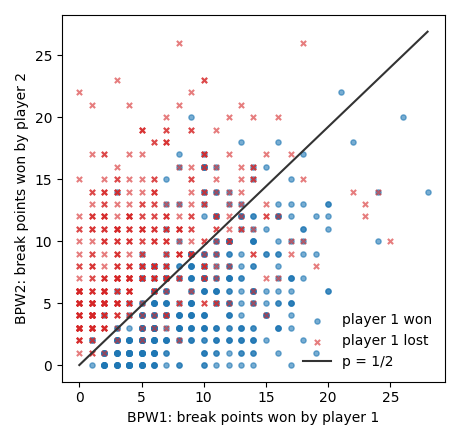

In [3]:
fig, ax = plt.subplots(figsize=(4.6, 4.4))
for won, marker, color, name in ((1, 'o', 'C0', 'player 1 won'), (0, 'x', 'C3', 'player 1 lost')):
    part = tennis[tennis.Result == won]
    ax.scatter(part.BPW1, part.BPW2, marker=marker, s=14, c=color, alpha=0.6, label=name)
boundary = smf.logit('Result ~ BPW1 + BPW2 - 1', data=tennis).fit(disp=0)
b1, b2 = boundary.params['BPW1'], boundary.params['BPW2']
xs = np.linspace(0, tennis.BPW1.max(), 50)
ax.plot(xs, -b1 / b2 * xs, color='0.2', lw=1.5, label='p = 1/2')
ax.set_xlabel('BPW1: break points won by player 1')
ax.set_ylabel('BPW2: break points won by player 2')
ax.legend(frameon=False)
fig.tight_layout()

Player 1's wins (blue dots) sit below the diagonal, where player 1 won more break points than player 2. Player 1's losses (red crosses) sit above it. Near the diagonal the two marks mix. Those are matches where both players won about the same number of break points, and break points alone cannot tell who won.

### 1.2 The fit, and a coefficient as an odds ratio

Fit `Result ~ BPW1 + BPW2 - 1`. The `- 1` removes the intercept, so the log of the odds is

$$
\log\frac{p}{1-p} = \beta_1 \,\mathrm{BPW1} + \beta_2 \,\mathrm{BPW2}.
$$

Add 1 to `BPW1` and the log odds go up by $\beta_1$, so the odds are multiplied by $e^{\beta_1}$. That factor is the odds ratio. It is the easiest way to read a logistic coefficient: "one more break point for player 1 multiplies player 1's odds of winning by $e^{\beta_1}$."

Before you run the cell: why is $p$ at $(0, 0)$ exactly $1/2$? And what should the signs of $\beta_1$ and $\beta_2$ be?

In [4]:
model = smf.logit('Result ~ BPW1 + BPW2 - 1', data=tennis).fit(disp=0)
odds = pd.DataFrame({
    'beta': model.params,
    'odds ratio': np.exp(model.params),
    'low 95%': np.exp(model.conf_int()[0]),
    'high 95%': np.exp(model.conf_int()[1]),
})
print(odds.round(3))
print()
points = pd.DataFrame({'BPW1': [0, 1, 3], 'BPW2': [0, 0, 0]})
points['p'] = model.predict(points)
print(points.round(3))

       beta  odds ratio  low 95%  high 95%
BPW1  0.402       1.495    1.419     1.574
BPW2 -0.418       0.658    0.623     0.695

   BPW1  BPW2      p
0     0     0  0.500
1     1     0  0.599
2     3     0  0.770


$\beta_1 = 0.402$ and $\beta_2 = -0.418$: about the same size and opposite in sign. A break point won by player 2 is the mirror of one won by player 1.

The odds ratio for `BPW1` is $e^{0.402} = 1.495$, printed as 1.50 below when rounded: each extra break point for player 1 multiplies player 1's odds of winning by about 1.5. The 95% interval is 1.42 to 1.57. The odds ratio for `BPW2` is $e^{-0.418} = 0.66$: each extra break point for player 2 cuts player 1's odds to about two-thirds.

The three probabilities:

- At $(0, 0)$ the log odds are 0, so the odds are 1 and $p = 1/2$. There is no intercept, so nothing else can move it.
- At $(1, 0)$ the odds are 1.495, so $p = 1.495/2.495 = 0.599$.
- At $(3, 0)$ the odds are $1.495^3 = 3.34$, so $p = 3.34/4.34 = 0.770$.

The odds ratio multiplies the odds, not $p$. The first break point adds 0.10 to $p$; each later one adds a little less.

### 1.3 A cutoff of one half

Pick player 1 when $p > 0.5$. The table that counts right and wrong picks is the confusion matrix. Rows are `won`, the value of `Result` (1 means player 1 won). Columns are `picked` (1 means the model picked player 1). Accuracy is the share of matches in the two correct cells.

The cutoff $p = 1/2$ is the line where the log odds are 0, $\beta_1\,\mathrm{BPW1} + \beta_2\,\mathrm{BPW2} = 0$. The cell draws it on the scatter.

picked    0    1
won             
0       416   61
1        65  400
accuracy 0.866
picked      0      1
won                 
0       44.16   6.48
1        6.90  42.46


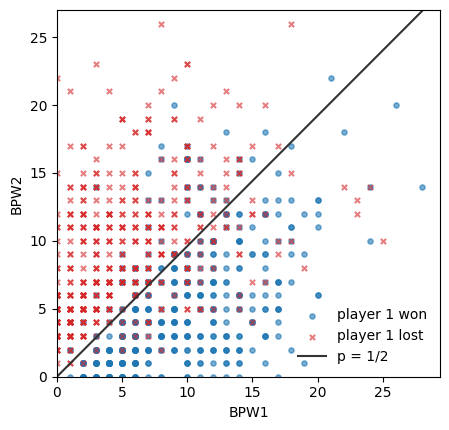

In [ ]:
p_win = model.predict(tennis)
picked = (p_win > 0.5).astype(int)
print(pd.crosstab(tennis.Result.rename('won'), picked.rename('picked')))
print(f'accuracy {(picked == tennis.Result).mean():.3f}')

b1, b2 = model.params['BPW1'], model.params['BPW2']
fig, ax = plt.subplots(figsize=(4.6, 4.4))
for won, marker, color, name in ((1, 'o', 'C0', 'player 1 won'), (0, 'x', 'C3', 'player 1 lost')):
    part = tennis[tennis.Result == won]
    ax.scatter(part.BPW1, part.BPW2, marker=marker, s=14, c=color, alpha=0.6, label=name)
xs = np.linspace(0, tennis.BPW1.max(), 50)
ax.plot(xs, -b1 / b2 * xs, color='0.2', lw=1.5, label='p = 1/2')
ax.set_xlim(left=0)
ax.set_ylim(0, tennis.BPW2.max() + 1)
ax.set_xlabel('BPW1')
ax.set_ylabel('BPW2')
ax.legend(frameon=False)
fig.tight_layout()
# Confusion matrix in percent of the 942 matches
counts = pd.crosstab(tennis.Result.rename('won'), picked.rename('picked'))
print((100 * counts / counts.to_numpy().sum()).round(2))


The model is right on $416 + 400 = 816$ of the 942 matches: accuracy 0.866. The two wrong cells hold 61 and 65 matches, almost the same, so the model does not lean toward one kind of mistake. The line $p = 1/2$ is $\mathrm{BPW2} = (0.402/0.418)\,\mathrm{BPW1} \approx 0.96\,\mathrm{BPW1}$, almost the diagonal. In words: pick the player who won more break points.

### 1.4 Are women's matches less predictable?

The deviance residual measures how far the fit missed one match. It is large when the model gave the actual result a low probability, and also, more mildly, when the model was unsure ($p$ near $1/2$) even if its pick was right. The next cell draws a box plot of the absolute residual for men and for women, and prints three numbers per group: the median absolute residual, the accuracy, and the average number of break points won in the match (`BPW1 + BPW2`).

Before you run it: if the women's box is higher, does that mean the model picks the wrong winner more often?

M
picked    0    1
won             
0       215   36
1        32  208
picked      0      1
won                 
0       43.79   7.33
1        6.52  42.36
W
picked    0    1
won             
0       201   25
1        33  192
picked      0      1
won                 
0       44.57   5.54
1        7.32  42.57
        matches  median_abs_resid  accuracy  mean_break_points
gender                                                        
M           491             0.573     0.862             16.057
W           451             0.703     0.871             12.262


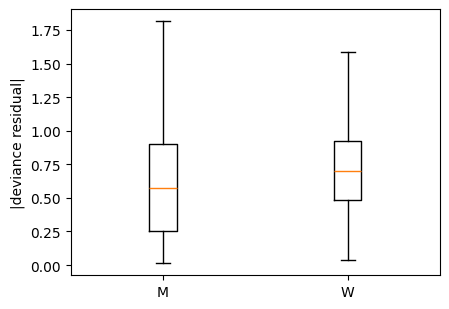

In [6]:
tennis['abs_resid'] = np.abs(model.resid_dev)
tennis['correct'] = (picked == tennis.Result)
tennis['break_points'] = tennis.BPW1 + tennis.BPW2

for g in ('M', 'W'):
    part = tennis[tennis.gender == g]
    tab = pd.crosstab(part.Result.rename('won'), picked.loc[part.index].rename('picked'))
    print(g)
    print(tab)
    print((100 * tab / tab.to_numpy().sum()).round(2))

def by_group(column):
    summary = tennis.groupby(column).agg(
        matches=('Result', 'size'),
        median_abs_resid=('abs_resid', 'median'),
        accuracy=('correct', 'mean'),
        mean_break_points=('break_points', 'mean'),
    )
    print(summary.round(3))
    fig, ax = plt.subplots(figsize=(4.6, 3.2))
    groups = list(summary.index)
    ax.boxplot([tennis.loc[tennis[column] == g, 'abs_resid'] for g in groups], showfliers=False)
    ax.set_xticks(range(1, len(groups) + 1), [str(g) for g in groups])
    ax.set_ylabel('|deviance residual|')
    fig.tight_layout()

by_group('gender')

The women's box is higher: median absolute residual 0.70, against 0.57 for men. The men's matrix is 215 and 208 correct, 36 and 32 wrong. The women's is 201 and 192 correct, 25 and 33 wrong. But the accuracy is the same: 0.871 for women and 0.862 for men. The model picks the winner of a women's match as often as the winner of a men's match.

The last column explains the residuals. Women's matches at the majors are best of three sets, so they have fewer break points: 12.3 on average, against 16.1. With fewer break points the gap between the two players is smaller, so $p$ is closer to $1/2$. A right pick made at $p = 0.6$ still has a residual of about 1.

So the plot does not show that women's matches are less predictable. It shows that the model is less sure about them. Always check a claim about residuals against the accuracy.

### 1.5 One more cut of the same matches

Run the same check by surface. Before you run it, predict: which surface has the largest residuals, and does it also have the lowest accuracy? Then try `by_group('Round')` in a new cell.

       matches  median_abs_resid  accuracy  mean_break_points
surf                                                         
Clay       252             0.529     0.837             17.702
Grass      236             0.724     0.949              6.208
Hard       454             0.595     0.839             16.493


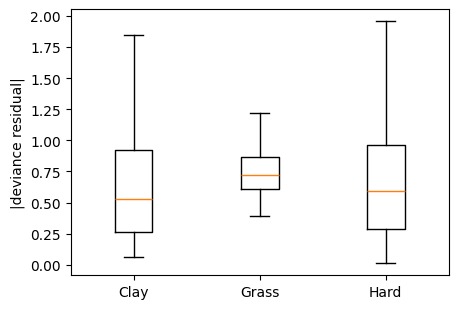

In [7]:
by_group('surf')

Grass has the largest residuals (median 0.72) and also the highest accuracy, 0.949. Grass matches have the fewest break points, 6.2 on average, because the serve is hard to break on grass. Once more the residual tracks how sure the model can be, not how often it is wrong. Clay (0.837) and hard courts (0.839) have about the same accuracy.

## 2. German credit

- 1,000 German loans. 300 were not repaid. `Default` is 1 for a loan that was not repaid.
- `history` is collapsed to good, poor, or terrible, and `purpose` to new car, used car, goods or repair, education, or business. These are the homework's labels.
- `foreign` is `foreign` for a foreign worker and `not_foreign` otherwise. `rent` is `yes` when the applicant rents.
- The model includes each of these on its own, and every product of two of them: duration, amount, installment, age, history, purpose, foreign, and rent.
- The comparison groups are good history, a new car, a foreign worker, and not renting. Each fitted number is the gap from that group, with the other inputs held the same.
- Some product columns are exact combinations of other columns, so they carry no new information and the fit cannot separate them. The cell finds and removes those columns before fitting. The printout says which.
- AIC is a score for a fitted model: how badly it fits, plus a cost for each extra term. Lower is better. It lets you compare models with different numbers of terms.
- In this section `p` in a table column means a p-value, not a probability. The text always writes "p-value" for it.

### 2.1 The big model

In [7]:
X.shape

(1000, 72)

In [4]:
import warnings

import patsy
import statsmodels.api as sm
from scipy.linalg import qr

credit = pd.read_csv(DATA / 'credit.csv')
credit['history'] = pd.Categorical(
    credit['history'].map({'A30': 'good', 'A31': 'good', 'A32': 'poor', 'A33': 'poor', 'A34': 'terrible'}),
    ['good', 'poor', 'terrible'])
credit['purpose'] = pd.Categorical(
    credit['purpose'].map({
        'A40': 'newcar', 'A41': 'usedcar',
        'A42': 'goods_repair', 'A43': 'goods_repair', 'A44': 'goods_repair', 'A45': 'goods_repair',
        'A46': 'edu', 'A48': 'edu', 'A49': 'biz', 'A410': 'biz'}),
    ['newcar', 'usedcar', 'goods_repair', 'edu', 'biz'])
credit['foreign'] = pd.Categorical(
    credit['foreign'].map({'A201': 'foreign', 'A202': 'not_foreign'}), ['foreign', 'not_foreign'])
credit['rent'] = pd.Categorical(np.where(credit.housing.eq('A151'), 'yes', 'no'), ['no', 'yes'])
print(f"{len(credit)} loans, {int(credit.Default.sum())} defaults")
print('foreign:', credit.foreign.value_counts().to_dict())

y, X = patsy.dmatrices(
    'Default ~ (duration + amount + installment + age + C(history) + C(purpose) + C(foreign) + C(rent))**2',
    credit, return_type='dataframe')
values = np.asarray(X, float)
_, r, piv = qr(values, pivoting=True, mode='economic')
diag = np.abs(np.diag(r))
rank = int(np.sum(diag > 1e-8 * diag[0]))
Xr = X.iloc[:, np.sort(piv[:rank])]
print(f'{X.shape[1]} columns built, {Xr.shape[1]} kept; removed:', [c for c in X.columns if c not in Xr.columns])

with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    full = sm.Logit(np.asarray(y).ravel(), Xr).fit(disp=0, maxiter=100)

table = pd.DataFrame({
    'coef': full.params,
    'std_err': full.bse,
    'z': full.tvalues,
    'p': full.pvalues,
}).sort_values('p')
print(f"{Xr.shape[1]} terms, AIC {full.aic:.1f}, terms with p-value < 0.1: {(table.p < 0.1).sum()}")
table.round(4)

1000 loans, 300 defaults
foreign: {'foreign': 963, 'not_foreign': 37}
72 columns built, 71 kept; removed: ['C(purpose)[T.edu]:C(foreign)[T.not_foreign]']
71 terms, AIC 1117.7, terms with p-value < 0.1: 14


,coef,std_err,z,p
duration:C(history)[T.terrible],0.1069,0.0376,2.8422,0.0045
C(purpose)[T.usedcar],-8.4015,3.0309,-2.7720,0.0056
age:C(purpose)[T.biz],0.0700,0.0280,2.4988,0.0125
amount:C(purpose)[T.usedcar],0.0003,0.0002,2.2467,0.0247
duration:amount,-0.0000,0.0000,-2.1865,0.0288
...,...,...,...,...
amount:C(history)[T.poor],-0.0000,0.0001,-0.1463,0.8837
C(history)[T.poor]:C(purpose)[T.biz],0.1069,0.9763,0.1095,0.9128
C(purpose)[T.usedcar]:C(rent)[T.yes],0.0857,1.1570,0.0741,0.9409
installment:C(rent)[T.yes],0.0067,0.2249,0.0298,0.9762


Four things to read in this output.

- Only 37 of the 1,000 loans went to non-foreign workers.
- 72 columns were built and one was removed: education loans by non-foreign workers. There are no such loans, so that column is all zeros.
- 14 of the 71 terms have a p-value below 0.1.
- The last row has coefficient $-15.7$ and standard error 32,448. It is used-car loans by non-foreign workers. There are only 2 such loans and neither defaulted, so the fit keeps pushing the coefficient toward minus infinity to give them a default chance of 0. Its p-value of 1.0 does not mean the effect is zero. It means the estimate is meaningless. Section 2.6 shows how a penalty stops this.

### 2.2 Reading coefficients as odds ratios

With 71 terms, most coefficients belong to products and cannot be read one at a time. A small model with each input on its own can. The next cell fits one and prints each odds ratio $e^{\beta}$ with its 95% interval. Amount is in thousands of marks: in the formula, `I(amount / 1000)` just means "compute amount / 1000 first".

In [9]:
small = smf.logit('Default ~ duration + I(amount / 1000) + age + C(history) + C(foreign) + C(rent)',
                  data=credit).fit(disp=0)
ratios = pd.DataFrame({
    'odds ratio': np.exp(small.params),
    'low 95%': np.exp(small.conf_int()[0]),
    'high 95%': np.exp(small.conf_int()[1]),
}).drop(index='Intercept')
ratios.round(3)

,odds ratio,low 95%,high 95%
C(history)[T.poor],0.340,0.212,0.546
C(history)[T.terrible],0.167,0.098,0.286
C(foreign)[T.not_foreign],0.318,0.103,0.979
C(rent)[T.yes],1.594,1.104,2.303
duration,1.031,1.016,1.047
I(amount / 1000),1.026,0.964,1.093
age,0.988,0.975,1.002


Read each row as "multiplies the odds of default by". An interval that contains 1 means the data cannot tell whether the odds go up or down.

- Duration: 1.031 per month, about 3% higher odds for each extra month. A loan 12 months longer has $1.031^{12} = 1.44$ times the odds.
- Renting: 1.59. Renters have 59% higher odds of default than applicants who do not rent.
- Non-foreign worker: 0.32, with a wide interval (0.10 to 0.98), because there are only 37 such loans.
- Amount and age: both intervals contain 1.
- History: "poor" has 0.34 and "terrible" has 0.17. Worse history, lower default?

The history result is not a mistake in the code. The labels come from the homework. In the original data, "terrible" is "critical account, with other credits elsewhere", and the bank lent to these applicants only when the rest of the application was strong. The data contain only the loans the bank chose to make. An odds ratio describes those loans. It is not the effect of having a bad history.

### 2.3 Keep the terms with p below 0.1

The homework's rule: keep a term of the big model if its p-value is below 0.1, and fit again with only those terms. The intercept is a term like the others, so it stays only if its own p-value is below 0.1.

In [9]:
keep = table.index[table.p < 0.1]
reduced = sm.Logit(np.asarray(y).ravel(), Xr[keep]).fit(disp=0)
print(f'kept {len(keep)} terms; intercept kept: {"Intercept" in keep}')
print(f'AIC: big model {full.aic:.1f}, reduced model {reduced.aic:.1f}')
print(f'terms with p-value still below 0.1 in the reduced model: {(reduced.pvalues < 0.1).sum()} of {len(keep)}')
print('p-value moved above 0.1:', list(reduced.pvalues.index[reduced.pvalues >= 0.1]))
keep

kept 14 terms; intercept kept: False
AIC: big model 1117.7, reduced model 1148.0
terms with p-value still below 0.1 in the reduced model: 8 of 14
p-value moved above 0.1: ['duration:C(history)[T.terrible]', 'age:C(purpose)[T.biz]', 'duration:C(history)[T.poor]', 'C(history)[T.poor]:C(purpose)[T.edu]', 'C(history)[T.terrible]:C(purpose)[T.edu]', 'age:C(purpose)[T.usedcar]']


Index(['duration:C(history)[T.terrible]', 'C(purpose)[T.usedcar]',
       'age:C(purpose)[T.biz]', 'amount:C(purpose)[T.usedcar]',
       'duration:amount', 'duration:C(history)[T.poor]',
       'C(history)[T.poor]:C(purpose)[T.edu]',
       'installment:C(purpose)[T.goods_repair]', 'C(purpose)[T.biz]',
       'C(history)[T.terrible]:C(purpose)[T.edu]', 'duration:C(rent)[T.yes]',
       'C(history)[T.poor]:C(rent)[T.yes]',
       'installment:C(history)[T.terrible]', 'age:C(purpose)[T.usedcar]'],
      dtype='str')

- The intercept had a p-value of at least 0.1, so the rule dropped it.
- AIC rose from 1117.7 to 1148.0, by 30.3. A higher AIC is a worse description of these loans.
- Only 8 of the 14 kept terms are still below 0.1. The six listed moved above it. A p-value depends on what else is in the model, so a term can look useful next to its partners and useless without them.
- Dropping the intercept is a mistake in its own right. With no intercept, the log odds are forced to 0, which means $p = 1/2$, for a loan whose inputs are all 0, and every other coefficient bends to make up for it. Keep the intercept whatever its p-value.

### 2.4 The ROC curve

A cutoff $t$ means: predict default when the probability $p > t$. Each cutoff has two rates:

$$
\mathrm{Sensitivity} = \frac{\text{defaults the rule catches}}{\text{defaults}}, \qquad
\mathrm{Specificity} = \frac{\text{repaid loans the rule calls repaid}}{\text{repaid loans}}.
$$

The false positive rate is $1 - \text{specificity}$: of the repaid loans, the share the rule wrongly calls defaults. The ROC curve plots sensitivity against the false positive rate for every cutoff. The next cell draws it for the big model, scored on the same 1,000 loans it was fitted to, and marks $t = 0.2$ and $t = 0.5$.

t = 0.2: sensitivity 0.880, false positive rate 0.519
t = 0.5: sensitivity 0.377, false positive rate 0.074


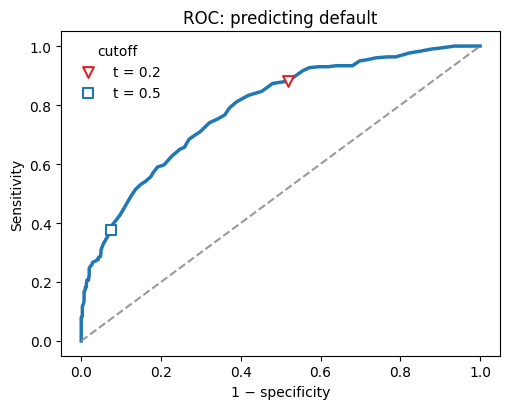

In [11]:
def roc(p, y, n_grid=100):
    p = np.asarray(p, dtype=float)
    y = np.asarray(y)
    grid = np.linspace(0, 1, n_grid)
    call = p[:, None] > grid[None, :]
    specificity = np.mean(~call[y == 0], axis=0) if np.any(y == 0) else np.ones(n_grid)
    sensitivity = np.mean(call[y == 1], axis=0) if np.any(y == 1) else np.zeros(n_grid)
    return grid, sensitivity, specificity

def roc_point(p, y, t):
    y = np.asarray(y)
    false_positive = 1 - np.mean(p[y == 0] < t)
    sensitivity = np.mean(p[y == 1] > t)
    return false_positive, sensitivity

# Positive class: the loan defaults. Predict default when p > t.
p_default = np.asarray(full.predict(Xr))
default = credit.Default.to_numpy()
grid, sensitivity, specificity = roc(p_default, default)

fig, ax = plt.subplots(figsize=(5.2, 4.2))
ax.plot(1 - specificity, sensitivity, color='C0', lw=2.5)
ax.plot([0, 1], [0, 1], color='0.6', ls='--')
for t_mark, marker, color in ((0.2, 'v', 'C3'), (0.5, 's', 'C0')):
    x, sens = roc_point(p_default, default, t_mark)
    ax.scatter([x], [sens], marker=marker, s=60, facecolors='white', edgecolors=color, linewidths=1.5, label=f't = {t_mark}', zorder=3)
    print(f't = {t_mark}: sensitivity {sens:.3f}, false positive rate {x:.3f}')
ax.set_xlabel('1 − specificity')
ax.set_ylabel('Sensitivity')
ax.set_title('ROC: predicting default')
ax.legend(frameon=False, title='cutoff')
fig.tight_layout()

- One cutoff is one point on the curve.
- Lowering $t$ moves up and to the right: more defaults caught, more good loans refused.
- The diagonal is a useless rule: it does no better than a coin.
- At $t = 0.2$ the rule catches 88.0% of the defaults and wrongly flags 51.9% of the good loans. At $t = 0.5$ it catches 37.7% of the defaults and flags 7.4% of the good loans.
- These numbers are flattering. The model was scored on the loans it was fitted to. The next part fixes that.

### 2.5 Scoring on loans the model has not seen

Split the loans: fit on 700, score on the other 300. The area under the ROC curve (AUC) summarizes the curve in one number: it is the chance that a random default gets a higher $p$ than a random repaid loan. 0.5 is a coin; 1 is perfect.

The big model cannot even be fitted on 700 loans: some of its 71 columns become exact combinations of the others in the smaller sample. So the cell compares the reduced model with the big model fitted with a penalty, which Section 2.6 explains. `C=1` is scikit-learn's default.

In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

y_all = np.asarray(y).ravel()
train, test = train_test_split(np.arange(len(credit)), test_size=300, random_state=1, stratify=y_all)

# The reduced model, refitted on the 700 training loans.
reduced_tr = sm.Logit(y_all[train], Xr[keep].iloc[train]).fit(disp=0)
p_reduced = np.asarray(reduced_tr.predict(Xr[keep].iloc[test]))

# The 71 terms with a penalty. The columns are put on one scale first, so one penalty fits all.
scaler = StandardScaler().fit(Xr.iloc[train].drop(columns='Intercept'))
Z_train = scaler.transform(Xr.iloc[train].drop(columns='Intercept'))
Z_test = scaler.transform(Xr.iloc[test].drop(columns='Intercept'))
penalized = LogisticRegression(C=1, max_iter=5000).fit(Z_train, y_all[train])
p_penalized = penalized.predict_proba(Z_test)[:, 1]

print(f'big model, all 1,000 loans (fitted on them): AUC {roc_auc_score(y_all, full.predict(Xr)):.3f}')
print(f'reduced model, 300 unseen loans:             AUC {roc_auc_score(y_all[test], p_reduced):.3f}')
print(f'71 terms with penalty C=1, 300 unseen loans: AUC {roc_auc_score(y_all[test], p_penalized):.3f}')

big model, all 1,000 loans (fitted on them): AUC 0.788
reduced model, 300 unseen loans:             AUC 0.650
71 terms with penalty C=1, 300 unseen loans: AUC 0.692


Scored on the loans it was fitted to, the big model has AUC 0.788. On loans it has not seen, the reduced model scores 0.650 and the penalized 71-term model 0.692. The 0.788 was too good to be true: part of what the big model learned was noise in those particular 1,000 loans. Always judge a model on data it was not fitted to. The reduced model also has no intercept, because the homework rule dropped it in 2.3. That is part of why it does worst.

### 2.6 The penalty

A plain logistic fit picks the coefficients that make the observed answers most likely. With many columns and few loans in some groups, that can push a coefficient toward infinity, as the 2 used-car loans to non-foreign workers did in 2.1. The penalty adds a cost for large coefficients:

$$
\text{minimize}\quad \sum_{\text{loans}} \bigl(-\log p \text{ of the answer that happened}\bigr) \;+\; \frac{1}{2C}\sum_j \beta_j^2 .
$$

This is the L2 penalty, the same idea as ridge regression in Part 1. A small $C$ means a strong penalty and small coefficients. A large $C$ means almost no penalty. The cell fits the 71 terms at several values of $C$ and prints the largest coefficient, the AUC, and the log loss on the 300 unseen loans. Log loss is the average $-\log p$ of what happened: lower is better. Predicting the training default rate for every loan gives the baseline log loss.

In [13]:
base_rate = y_all[train].mean()
print(f'baseline: p = {base_rate:.2f} for every loan, log loss {log_loss(y_all[test], np.full(len(test), base_rate)):.3f}')
for C in (100, 1, 0.1, 0.01, 0.001):
    m = LogisticRegression(C=C, max_iter=5000).fit(Z_train, y_all[train])
    p = m.predict_proba(Z_test)[:, 1]
    print(f'C = {C:<6} largest |coef| {np.abs(m.coef_).max():5.2f}   '
          f'AUC {roc_auc_score(y_all[test], p):.3f}   log loss {log_loss(y_all[test], p):.3f}')

baseline: p = 0.30 for every loan, log loss 0.611
C = 100    largest |coef|  5.66   AUC 0.689   log loss 0.677
C = 1      largest |coef|  1.46   AUC 0.692   log loss 0.589
C = 0.1    largest |coef|  0.43   AUC 0.698   log loss 0.573
C = 0.01   largest |coef|  0.16   AUC 0.700   log loss 0.566
C = 0.001  largest |coef|  0.05   AUC 0.689   log loss 0.579


- Almost no penalty ($C = 100$): the largest coefficient is 5.66 (on the rescaled columns), and the log loss, 0.677, is worse than the baseline 0.611. The model is so sure of itself that its mistakes cost a lot.
- As $C$ falls, the coefficients shrink and the log loss improves. It is best at $C = 0.01$: log loss 0.566, AUC 0.700.
- At $C = 0.001$ the penalty is too strong, and both get worse again.
- AUC barely moves from $C = 100$ to $C = 0.01$ (0.689 to 0.700), while log loss moves a lot. AUC only checks whether defaults are ranked above repaid loans. Log loss checks the probabilities themselves.

One caution. This cell looks at the same 300 loans for every $C$, so once you pick the best $C$ from this table, those loans have helped choose the model and are no longer truly unseen. Here the table only shows the trend. In real work, pick $C$ by cross-validation on the training loans (2.7 explains cross-validation), and keep the test loans for the final score.

### 2.7 Calibration: is p really a probability?

The cost rule in 2.8 compares $p$ with a number. That only works if $p$ is a real probability: among loans given $p \approx 0.3$, about 30% should default.

300 unseen loans are too few to check this in groups, so the cell uses a standard trick, 10-fold cross-validation: split the 1,000 loans into 10 parts, fit on 9 parts, predict the 10th, and repeat until every loan has a prediction from a model that never saw it. It does this twice, with almost no penalty ($C = 100$) and with a strong one ($C = 0.01$). Then it sorts the loans by $p$, cuts them into five groups of 200, and prints the average $p$ next to the actual default rate in each group. A calibrated model has the two columns close.

In [14]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline

folds = StratifiedKFold(10, shuffle=True, random_state=1)
X_terms = Xr.drop(columns='Intercept')

def cv_probability(C):
    # Every loan is predicted by a model fitted on the other nine parts.
    fit = make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=5000))
    return cross_val_predict(fit, X_terms, y_all, cv=folds, method='predict_proba')[:, 1]

def calibration(p, outcome, groups=5):
    frame = pd.DataFrame({'p': p, 'default': outcome})
    frame['group'] = pd.qcut(frame.p.rank(method='first'), groups, labels=False) + 1
    return frame.groupby('group').agg(mean_p=('p', 'mean'), default_rate=('default', 'mean'))

p_weak = cv_probability(100)
p_strong = cv_probability(0.01)
print('almost no penalty, C = 100')
print(calibration(p_weak, y_all).round(3))
print()
print('strong penalty, C = 0.01')
print(calibration(p_strong, y_all).round(3))

almost no penalty, C = 100


       mean_p  default_rate
group                      
1       0.039         0.130
2       0.150         0.185
3       0.257         0.275
4       0.389         0.405
5       0.662         0.505

strong penalty, C = 0.01
       mean_p  default_rate
group                      
1       0.127         0.105
2       0.211         0.165
3       0.277         0.310
4       0.355         0.380
5       0.526         0.540


With almost no penalty the extreme groups are wrong. The lowest group is given 3.9% and defaults 13.0% of the time; the highest is given 66.2% and defaults 50.5%. The model is overconfident. With $C = 0.01$ every group is within 5 points of its actual default rate. Only calibrated probabilities can be compared with a cutoff like 0.2.

### 2.8 The cutoff comes from the costs

Making a loan gains \$0.25 per dollar if it is repaid and loses the dollar if it defaults. For a loan with default chance $p$, the expected gain is

$$
0.25(1-p) - 1\cdot p = 0.25 - 1.25p,
$$

which is positive when $p < 1/5$. So: lend when the chance of default is below 0.2. Refusing a loan that would have been repaid gives up 0.25; missing a default costs 1. Those two costs put the cutoff at $1/5$ rather than $1/2$.

The cell checks this with the cross-validated probabilities of the strongly penalized model ($C = 0.01$) from 2.7, so every loan is judged by a model that never saw it. It prints the share of applicants who get a loan, the default rate among them, and the average gain per applicant, for three rules: lend to everyone, lend when $p < 0.5$, and lend when $p < 0.2$.

In [15]:
outcome = y_all
print(f'a rule that never predicts default is right on {1 - y_all.mean():.0%} of all loans')
for name, lend in (('lend to all', np.ones(len(outcome), bool)),
                   ('p < 0.5', p_strong < 0.5),
                   ('p < 0.2', p_strong < 0.2)):
    gain = np.where(lend, np.where(outcome == 0, 0.25, -1.0), 0.0)
    print(f'{name:12} lend to {lend.mean():.0%}, default rate among them {outcome[lend].mean():.3f}, '
          f'gain per applicant {gain.mean():+.3f}')

a rule that never predicts default is right on 70% of all loans
lend to all  lend to 100%, default rate among them 0.300, gain per applicant -0.125
p < 0.5      lend to 90%, default rate among them 0.273, gain per applicant -0.082
p < 0.2      lend to 27%, default rate among them 0.109, gain per applicant +0.031


- Lend to everyone: 30% of the loans default, too many for a 25% margin, and the bank loses 12.5 cents per applicant. This is also the rule that never predicts default, the one that is right on 70% of the loans. High accuracy, and it loses money.
- Cutoff 0.5: lends to 90% and still loses 8.2 cents per applicant.
- Cutoff 0.2, the one that comes from the costs: lends to 27%, the default rate among them falls to 10.9%, and the bank gains 3.1 cents per applicant. It is the only one of the three rules that makes money.

The model supplies $p$. The costs supply the cutoff. Section 5 uses the same idea: there the cutoff is the break-even chance $1/O$.

## 3. Softmax

- $K$ classes. One score $z_k$ per class. Softmax turns the scores into probabilities that sum to 1:

$$
p_k = \frac{e^{z_k}}{\sum_{j=1}^{K} e^{z_j}}.
$$

- Subtract the largest score before taking $e^{z}$. The probabilities stay the same, and the calculation does not overflow.
- The scores do not have to sum to 1. The probabilities do.
- The loss is $-\log p$ for the class that happened.
- With two classes, set one score to 0. Softmax then becomes the logistic formula above.
- The predicted class is the one with the largest probability.

### 3.1 Three classes in the plane

Each class gets its own straight-line score, $z_k = \beta_k^\top x + b_k$. The fit uses scikit-learn's default L2 penalty with $C = 1$, the penalty of Section 2.6.

accuracy 1.000
probabilities at (0, 0.8): [[0.905 0.047 0.047]]
the three borders meet at [-0.012 -0.053] with probabilities [[0.333 0.333 0.333]]


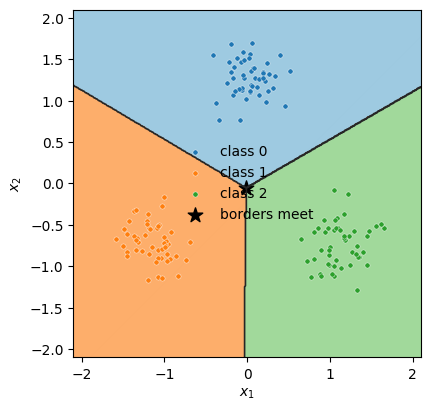

In [16]:
from sklearn.linear_model import LogisticRegression

rng = np.random.default_rng(2)
centers = np.array([[0.0, 1.3], [-1.15, -0.7], [1.15, -0.7]])
X3 = np.vstack([rng.normal(loc=c, scale=0.22, size=(50, 2)) for c in centers])
y3 = np.repeat([0, 1, 2], 50)
three = LogisticRegression().fit(X3, y3)
print(f'accuracy {three.score(X3, y3):.3f}')
print('probabilities at (0, 0.8):', np.round(three.predict_proba([[0.0, 0.8]]), 3))
# The point where all three scores are equal: z_0 = z_1 and z_0 = z_2.
W, b = three.coef_, three.intercept_
meet = np.linalg.solve(W[1:] - W[0], b[0] - b[1:])
print('the three borders meet at', np.round(meet, 3), 'with probabilities', np.round(three.predict_proba([meet]), 3))

grid = np.linspace(-2.1, 2.1, 400)
xx, yy = np.meshgrid(grid, grid)
regions = three.predict(np.column_stack([xx.ravel(), yy.ravel()])).reshape(xx.shape)
fig, ax = plt.subplots(figsize=(4.4, 4.4))
ax.contourf(xx, yy, regions, levels=[-0.5, 0.5, 1.5, 2.5], colors=['#9ecae1', '#fdae6b', '#a1d99b'])
ax.contour(xx, yy, regions, levels=[0.5, 1.5], colors='0.15', linewidths=1.2)
for k, color, name in ((0, 'C0', 'class 0'), (1, 'C1', 'class 1'), (2, 'C2', 'class 2')):
    ax.scatter(X3[y3 == k, 0], X3[y3 == k, 1], s=14, c=color, edgecolors='white', linewidths=0.3, label=name)
ax.set_aspect('equal')
ax.set_xlabel(r'$x_1$')
ax.set_ylabel(r'$x_2$')
ax.scatter(*meet, marker='*', s=120, c='k', label='borders meet')
ax.legend(frameon=False)
fig.tight_layout()

- One straight line cannot separate all three clouds, but three straight-line scores can.
- The border between class $j$ and class $k$ is where those two scores are equal and both are larger than the third.
- Every point is classified correctly (accuracy 1.000). At $(0, 0.8)$, inside the top cloud, the probabilities are 0.905, 0.047, and 0.047. The three borders meet at the star, near $(-0.01, -0.05)$, where all three scores are equal and each class has probability $1/3$.

### 3.2 The next word is the same softmax

- A language model gives a probability for every possible next piece of text, given the pieces already written.
- A token is a word, a piece of a word, or a character.
- Here the classes are the words that have followed the current word. The score of a word is the log of how often it followed.
- The book uses a long prompt. Here the text is a tiny corpus of six sentences you can count by hand, and the current word is "model".

In [17]:
from collections import Counter

lines = [
    'the model learns from data .',
    'the model learns from data .',
    'the model learns from text .',
    'the model predicts the winner .',
    'a horse wins the race .',
    'a horse wins the bet .',
]
follows = Counter()
for line in lines:
    words = line.split()
    for left, right in zip(words, words[1:]):
        follows[(left, right)] += 1

def softmax(scores, temperature=1.0):
    z = np.asarray(scores, float) / temperature
    z = z - z.max()
    w = np.exp(z)
    return w / w.sum()

def candidates(context):
    rows = [(right, n) for (left, right), n in follows.items() if left == context]
    rows.sort(key=lambda row: -row[1])
    return rows

context = 'model'
words, counts = zip(*candidates(context))
scores = np.log(counts)
probability = softmax(scores)
for word, count, prob in zip(words, counts, probability):
    print(f'{word:10} count {count}  p {prob:.3f}  loss if this word came next {-np.log(prob):.3f}')
print('sum', probability.sum())

learns     count 3  p 0.750  loss if this word came next 0.288
predicts   count 1  p 0.250  loss if this word came next 1.386
sum 1.0


- After "model", "learns" has count 3 and "predicts" has count 1.
- The probabilities are 0.75 and 0.25. They sum to 1.
- The loss is $-\log p$ for the word that actually came next. If the next word was "learns", the loss is 0.29. If it was "predicts", the loss is 1.39.

### 3.3 Temperature

Temperature $T$ divides the scores before the softmax: $p_k \propto e^{z_k / T}$. A high temperature flattens the probabilities; a low one sharpens them. It never changes which word has the largest probability.

Before you run: at temperature 2, does "learns" still have probability 0.75?

In [18]:
words, counts = zip(*candidates('model'))
for temperature in (0.5, 1, 2):
    print(f'temperature {temperature}:', ', '.join(f'{w} {p:.3f}' for w, p in zip(words, softmax(np.log(counts), temperature))))

temperature 0.5: learns 0.900, predicts 0.100
temperature 1: learns 0.750, predicts 0.250
temperature 2: learns 0.634, predicts 0.366


At temperature 1 the probabilities are the shares of the counts, 0.75 and 0.25. At temperature 2, "learns" falls to 0.634 and "predicts" rises to 0.366: flatter. At temperature 0.5, "learns" rises to 0.900: sharper. "learns" stays on top at every temperature.

### 3.4 Writing a sentence: take the top word, or draw one

There are two ways to pick the next word. Greedy: always take the most probable word. Sampling: draw a word at random with the softmax probabilities. Temperature only matters for sampling, because it does not change which word is on top. The cell writes the greedy sentence, then draws 1,000 next words after "model" at temperatures 1 and 2 and counts how often "predicts" comes out.

In [19]:
def next_word(word, temperature, rng=None):
    words, counts = zip(*candidates(word))
    if rng is None:  # greedy
        return words[0]
    return rng.choice(words, p=softmax(np.log(counts), temperature))

word, sentence = 'the', ['the']
while word != '.' and len(sentence) < 10:
    word = next_word(word, temperature=1)
    sentence.append(word)
print('greedy:', ' '.join(sentence))

rng = np.random.default_rng(0)
for temperature in (1, 2):
    draws = [next_word('model', temperature, rng) for _ in range(1000)]
    print(f'temperature {temperature}: "predicts" drawn {draws.count("predicts")} times in 1,000')

greedy: the model learns from data .
temperature 1: "predicts" drawn 267 times in 1,000
temperature 2: "predicts" drawn 346 times in 1,000


The greedy sentence is "the model learns from data ." at every temperature, because the top word never changes. Sampling is different. "predicts" comes out 267 times in 1,000 at temperature 1, where its probability is 0.25, and 346 times at temperature 2, where its probability is 0.366. The counts are close to the probabilities but not equal to them, because the draws are random. This is what the temperature control in the next-token lab does.

## 4. The kernel trick

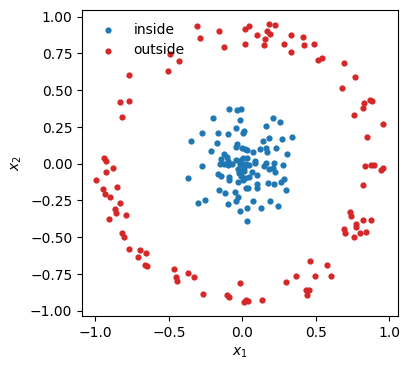

In [20]:
def circle_data(n=200, radius=1.0, noise=0.001, seed=13):
    rng = np.random.default_rng(seed)
    rows = np.zeros((n, 3))
    for i in range(n // 2):
        r = rng.uniform(0, radius * 0.4)
        angle = rng.uniform(0, 2 * np.pi)
        rows[i, 1] = r * np.sin(angle) + rng.uniform(-radius, radius) * noise
        rows[i, 2] = r * np.cos(angle) + rng.uniform(-radius, radius) * noise
    for i in range(n // 2, n):
        r = rng.uniform(radius * 0.8, radius)
        angle = rng.uniform(0, 2 * np.pi)
        rows[i, 0] = 1
        rows[i, 1] = r * np.sin(angle) + rng.uniform(-radius, radius) * noise
        rows[i, 2] = r * np.cos(angle) + rng.uniform(-radius, radius) * noise
    return rows

circle = circle_data()
x1, x2, yc = circle[:, 1], circle[:, 2], circle[:, 0]
Xc = np.column_stack([x1, x2])

fig, ax = plt.subplots(figsize=(4.2, 4.2))
for label, color, name in ((0, 'C0', 'inside'), (1, 'C3', 'outside')):
    ax.scatter(x1[yc == label], x2[yc == label], s=12, c=color, label=name)
ax.set_aspect('equal')
ax.set_xlabel(r'$x_1$')
ax.set_ylabel(r'$x_2$')
ax.legend(frameon=False)
fig.tight_layout()

- Points inside a circle, and points outside it. No straight line separates the two groups.

- The fix is to map each point to new coordinates where a flat plane can separate the groups. The map is

$$
\phi(x_1, x_2) = \bigl(u_1, u_2, u_3\bigr) = \bigl(x_1^2,\; \sqrt{2}\, x_1 x_2,\; x_2^2\bigr).
$$

- The inner product of two points $a$ and $b$ is $a^\top b = a_1 b_1 + a_2 b_2$. The next cell checks, for every pair of points, that the inner product of the mapped points equals the square of the original inner product: $\phi(a)^\top\phi(b) = (a^\top b)^2$. Then it plots the mapped points in 3D.

True


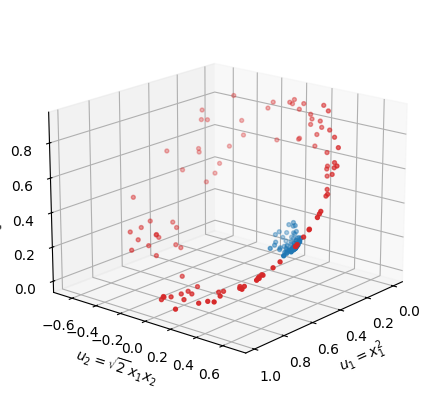

In [21]:
def phi(x1, x2):
    return np.column_stack([x1**2, np.sqrt(2) * x1 * x2, x2**2])

Z = phi(x1, x2)
# The kernel replaces the mapped inner product.
print(np.allclose(Z @ Z.T, (Xc @ Xc.T) ** 2))

fig = plt.figure(figsize=(5.2, 4.2))
ax = fig.add_subplot(111, projection='3d')
for label, color in ((0, 'C0'), (1, 'C3')):
    ax.scatter(Z[yc == label, 0], Z[yc == label, 1], Z[yc == label, 2], s=8, c=color)
ax.set_xlabel(r'$u_1 = x_1^2$')
ax.set_ylabel(r'$u_2 = \sqrt{2}\,x_1 x_2$')
ax.set_zlabel(r'$u_3 = x_2^2$')
ax.view_init(elev=18, azim=40)
fig.tight_layout()

- The check prints `True`. The square $(a^\top b)^2$ is called the polynomial kernel.
- In the new coordinates the inner cloud sits near the corner $(0, 0, 0)$ and the outer cloud farther away, so a flat plane can separate them. Drawn back in the original $x$, that plane is

$$
\beta_1 x_1^2 + \beta_2 \sqrt{2}\, x_1 x_2 + \beta_3 x_2^2 + b = 0,
$$

a closed curve around the inner cloud.
- Why the kernel matters: some methods only ever need the inner products between pairs of points. A support vector machine (SVM) is one: it is another classifier that draws a border between two groups, and it only uses $a^\top b$ for each pair. Give it $(a^\top b)^2$ instead and it works in the $\phi$ coordinates without ever computing $\phi$. Here $\phi$ has 3 coordinates, so computing it is cheap. The kernel matters when $\phi$ would have millions.

### 4.1 A line, a curve, and the kernel

The cell fits three models. A logistic regression on $(x_1, x_2)$, which can only draw a straight line. The same logistic regression on $\phi(x)$, which draws the curve. And a support vector machine on $(x_1, x_2)$ with the kernel $(a^\top b)^2$, which never builds $\phi$. The groups do not overlap, so without a penalty the logistic coefficients would grow without limit; both logistic fits use the default L2 penalty, $C = 1$. The classes are 100 and 100, so guessing gives 50%. Guess the three accuracies before you run the cell.

line   0.525
phi    1.000
kernel 1.000


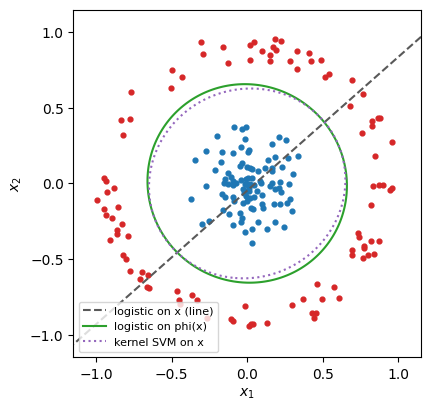

In [22]:
from sklearn.svm import SVC

line = LogisticRegression().fit(Xc, yc)
curve = LogisticRegression().fit(Z, yc)
kernel = SVC(kernel='poly', degree=2, gamma=1, coef0=0).fit(Xc, yc)
print(f"line   {line.score(Xc, yc):.3f}")
print(f"phi    {curve.score(Z, yc):.3f}")
print(f"kernel {kernel.score(Xc, yc):.3f}")

grid = np.linspace(-1.15, 1.15, 250)
xx, yy = np.meshgrid(grid, grid)
flat = np.column_stack([xx.ravel(), yy.ravel()])
fig, ax = plt.subplots(figsize=(4.4, 4.4))
for label, color in ((0, 'C0'), (1, 'C3')):
    ax.scatter(x1[yc == label], x2[yc == label], s=12, c=color)
ax.contour(xx, yy, line.decision_function(flat).reshape(xx.shape), levels=[0], colors='0.35', linestyles='--')
ax.contour(xx, yy, curve.decision_function(phi(xx.ravel(), yy.ravel())).reshape(xx.shape), levels=[0], colors='C2')
ax.contour(xx, yy, kernel.decision_function(flat).reshape(xx.shape), levels=[0], colors='C4', linestyles=':')
ax.plot([], [], color='0.35', ls='--', label='logistic on x (line)')
ax.plot([], [], color='C2', label='logistic on phi(x)')
ax.plot([], [], color='C4', ls=':', label='kernel SVM on x')
ax.legend(frameon=True, loc='lower left', fontsize=8)
ax.set_aspect('equal')
ax.set_xlabel(r'$x_1$')
ax.set_ylabel(r'$x_2$')
fig.tight_layout()

The straight line is right 52.5% of the time, no better than the 50% from guessing: no straight line separates a circle. The logistic fit on $\phi(x)$ and the kernel SVM on $x$ are both right every time, and their curves (green, and purple dotted; see the legend) are nearly the same circle. The SVM got there without ever computing $\phi$: it only used $(a^\top b)^2$.

## 5. Betting: how Benter sizes a bet

Bill Benter made a fortune betting on horse races in Hong Kong. Before each race he answered two questions: which horse to bet on, and how many dollars to bet. Part A follows his recipe through one real race, one step at a time. Part B checks the crowd's chances on 5,885 favorites, the Horse Race Betting example in Chapter 13.

The symbols in this section, with their values for horse 3 in Part A:

| Symbol | In plain words | Horse 3 |
|---|---|---|
| $O$ | The odds on the board: what a winning \$1 ticket pays back, the \$1 included | 3.5 |
| $O - 1$ | The profit on a winning \$1 ticket | 2.5 |
| $1/O$ | The break-even chance: the bet makes money on average only if the horse wins more often than this | 0.286 |
| $q$ | The crowd's chance that the horse wins, read from the odds | 0.234 |
| $c$ | Benter's chance that the horse wins | 0.244 in Step 4; 0.32 in the Step 6 what-if |
| $cO - 1$ | The edge: the expected profit on a \$1 bet | $-0.147$ in Step 5; 0.120 in Step 6 |
| $f$ | The share of his bankroll that he bets | 0.048 in Step 7 |

How the crowd's chance $q$ is calculated, for horse 3 (Steps 1 to 3 below do the same for every horse):

1. Take $1/O$ for each horse. Horse 3: $1/3.5 = 0.286$.
2. Add up $1/O$ over all ten horses in the race. Here the sum is 1.2234. It is more than 1 because the track keeps a cut of every dollar bet (Step 2).
3. Divide each horse's $1/O$ by that sum. Horse 3: $q = 0.286 / 1.2234 = 0.234$.

$$
q = \frac{1/O}{\sum_{\text{all horses in the race}} 1/O}.
$$

After step 3 the ten values of $q$ add up to 1, so they can be read as chances.

The recipe has nine steps.

1. Read the odds board.
2. Measure the track's cut.
3. Turn the odds into the crowd's chances $q$.
4. Correct the crowd's chances. The result is Benter's chances $c$.
5. Test each horse. Bet only if the edge $cO - 1$ is above 0.
6. A what-if: a horse that passes the test.
7. Size the bet with the Kelly fraction $f$.
8. Turn $f$ into dollars, and bet half of it.
9. Put the whole recipe in one function.

### Part A. One race, from the odds board to a dollar amount

#### Step 1. Read the odds board

Race 1159 ran at Happy Valley on 25 November 1998, with ten horses. The next cell types in the final odds $O$ from the board. Horse 3 has the lowest odds, 3.5, so it is the crowd's favorite. A winning \$1 ticket on horse 3 pays back \$3.50: the \$1 stake plus \$2.50 profit.

The break-even chance is $1/O$. For horse 3 it is $1/3.5 = 2/7 = 0.286$. Check: a \$1 bet that earns \$2.50 with chance $2/7$ and loses the \$1 with chance $5/7$ has expected profit $\tfrac{2}{7} \times 2.50 - \tfrac{5}{7} \times 1 = \tfrac{5}{7} - \tfrac{5}{7} = 0$.

In [23]:
race = pd.DataFrame({
    'horse': range(1, 11),
    'O': [8.1, 9.5, 3.5, 19.0, 9.7, 13.0, 6.0, 6.2, 14.0, 13.0],
})
race['break_even'] = 1 / race.O
race.round(3)

,horse,O,break_even
0,1,8.1,0.123
1,2,9.5,0.105
2,3,3.5,0.286
3,4,19.0,0.053
4,5,9.7,0.103
5,6,13.0,0.077
6,7,6.0,0.167
7,8,6.2,0.161
8,9,14.0,0.071
9,10,13.0,0.077


Horse 3 breaks even at 0.286. The longest shot, horse 4 at odds 19.0, breaks even at 0.053.

#### Step 2. Measure the track's cut

Add up the break-even chances of all ten horses. If the track kept nothing, the sum would be exactly 1. It is above 1, because the track keeps a share of every dollar bet, the cut, and pays only the rest, $1 - \text{cut}$, to the winners. That makes every odds $O$ smaller by the factor $1 - \text{cut}$, so every $1/O$ is larger by the factor $1/(1 - \text{cut})$, and so is their sum: $\sum 1/O = 1/(1 - \text{cut})$. Solve for the cut:

$$
\text{cut} = 1 - \frac{1}{\sum 1/O}.
$$

In [24]:
total = race.break_even.sum()
cut = 1 - 1 / total
print(f'sum of 1/O = {total:.4f}')
print(f'track cut  = {cut:.3f}')

sum of 1/O = 1.2234
track cut  = 0.183


The sum is 1.2234, so the cut is 0.183. Of every \$1 bet on this race, the track kept about 18 cents and paid about 82 cents to the winning tickets. The Hong Kong Jockey Club deducts 17.5% from the win pool, close to this.

#### Step 3. Turn the odds into the crowd's chances

The break-even chances add to 1.2234, so they are not chances yet. The cut made every one of them larger by the same factor, so dividing each by the sum removes the cut. The results add to 1, and they are the crowd's chances $q$:

$$
q = \frac{1/O}{\sum 1/O}.
$$

Before you run the cell, predict $q \times O$ for horse 3. Hint: $q \times O = \frac{1/O}{\sum 1/O} \times O = \frac{1}{\sum 1/O}$, the same number for every horse.

In [25]:
race['q'] = race.break_even / total
race['q_times_O'] = race.q * race.O
print(f'sum of q = {race.q.sum():.3f}')
race.round(3)

sum of q = 1.000


,horse,O,break_even,q,q_times_O
0,1,8.1,0.123,0.101,0.817
1,2,9.5,0.105,0.086,0.817
2,3,3.5,0.286,0.234,0.817
3,4,19.0,0.053,0.043,0.817
4,5,9.7,0.103,0.084,0.817
5,6,13.0,0.077,0.063,0.817
6,7,6.0,0.167,0.136,0.817
7,8,6.2,0.161,0.132,0.817
8,9,14.0,0.071,0.058,0.817
9,10,13.0,0.077,0.063,0.817


Horse 3 has $q = 0.234$. The crowd gives it about a 23% chance, below the 28.6% it needs to break even. The column `q_times_O` is 0.817 for every horse, and $0.817 = 1 - \text{cut}$. In words: if the crowd's chances are right, every \$1 bet in this race pays back 82 cents on average, whichever horse you pick. To make money on a horse, Benter's chance $c$ must be above its break-even chance $1/O$, which is $q / (1 - \text{cut})$. For horse 3 that is $0.234 / 0.817 = 0.286$.

#### Step 4. Correct the crowd's chances

The crowd is good but not perfect. Favorites win a little more often than the crowd's chance says, and longshots a little less often. Benter's simplest correction raises every crowd chance to one power $\alpha$, then rescales so the ten chances add to 1 again:

$$
c = \frac{q^{\alpha}}{\sum q^{\alpha}}.
$$

With $\alpha = 1$ nothing changes, and $c = q$. With $\alpha$ above 1, the horses with the highest chances gain a little and the rest lose a little. Since $q^{\alpha} = e^{\alpha \log q}$, this is the softmax of Section 3 of this notebook, with scores $\alpha \log q$.

The value $\alpha = 1.06$ was fitted by maximum likelihood on the Hong Kong races in the data: 5,885 races, minus 12 dead heats with two winners, leaves 5,873. Maximum likelihood picks the $\alpha$ that makes the actual winners most likely: it maximizes the product, over all races, of $c$ for the horse that won. The race files are not in this notebook, so the next cell types the value in.

Section 2 of the [Benter betting lab](https://vsokolov.org/labs/benter-lab.html) puts $\alpha$ on the log-odds $\log(q/(1-q))$ instead of on $\log q$. That version changes the chances even at $\alpha = 1$, so its fitted $\alpha$ is a different number. Benter's paper uses $\log q$, as here.

In [26]:
alpha = 1.06
race['c'] = race.q**alpha / (race.q**alpha).sum()
race[['horse', 'O', 'break_even', 'q', 'c']].round(3)

,horse,O,break_even,q,c
0,1,8.1,0.123,0.101,0.100
1,2,9.5,0.105,0.086,0.085
2,3,3.5,0.286,0.234,0.244
3,4,19.0,0.053,0.043,0.041
4,5,9.7,0.103,0.084,0.083
5,6,13.0,0.077,0.063,0.061
6,7,6.0,0.167,0.136,0.138
7,8,6.2,0.161,0.132,0.133
8,9,14.0,0.071,0.058,0.056
9,10,13.0,0.077,0.063,0.061


Horse 3 goes from $q = 0.234$ to $c = 0.244$. Horse 4, the longest shot, goes from 0.043 to 0.041. The changes are small: one percentage point for the favorite.

#### Step 5. Test each horse: is the edge above 0?

The edge is the expected profit on a \$1 bet, computed with Benter's chance $c$. The ticket earns $O - 1$ with chance $c$ and loses the \$1 with chance $1 - c$:

$$
\text{edge} = c\,(O - 1) - (1 - c) = cO - 1.
$$

He bets on a horse only if its edge is above 0. That is the same as $c > 1/O$: his chance must beat the break-even chance from Step 1.

In [27]:
race['edge'] = race.c * race.O - 1
race[['horse', 'O', 'break_even', 'c', 'edge']].round(3)

,horse,O,break_even,c,edge
0,1,8.1,0.123,0.100,-0.189
1,2,9.5,0.105,0.085,-0.196
2,3,3.5,0.286,0.244,-0.147
3,4,19.0,0.053,0.041,-0.229
4,5,9.7,0.103,0.083,-0.197
5,6,13.0,0.077,0.061,-0.211
6,7,6.0,0.167,0.138,-0.174
7,8,6.2,0.161,0.133,-0.175
8,9,14.0,0.071,0.056,-0.215
9,10,13.0,0.077,0.061,-0.211


Every edge is negative. The best one is horse 3's, $-0.147$: a \$1 bet on horse 3 loses about 15 cents on average. Horse 3 needs $c$ above 0.286 and has 0.244, so it is 4.2 percentage points short. **Benter does not bet on this race.**

This is the usual answer. Over all 5,885 races in the data, the correction of Step 4 finds no bet at all, apart from 30 races whose recorded odds are wrong: in those races the cut computed as in Step 2 is under 4%, instead of about 18%. A small correction of the crowd cannot beat an 18% cut. Benter beat it with a much richer model: more than a hundred facts about each horse, combined with the crowd's chance.

#### Step 6. A what-if: a horse that passes the test

We do not have Benter's full model. To see how a bet is sized, suppose his full model gives horse 3 the chance $c = 0.32$, and lowers the other nine horses so the ten chances still add to 1. **The number 0.32 is made up for this example. It is not from the data.**

Now $c = 0.32$ is above the break-even chance 0.286, so the edge is positive. The other nine horses failed the test in Step 5 and are now lower still, so horse 3 is the only bet in this race.

In [28]:
c3 = 0.32
O3 = 3.5
edge3 = c3 * O3 - 1
print(f'edge = {c3} x {O3} - 1 = {edge3:.3f}')

edge = 0.32 x 3.5 - 1 = 0.120


The edge is 0.120: on average, each \$1 bet on horse 3 makes 12 cents. The edge says the bet is worth making. It does not say how much to bet. That is Step 7.

#### Step 7. Size the bet with the Kelly fraction

Benter bet a share $f$ of his bankroll, the money he set aside for betting. The Kelly rule picks the share that makes the bankroll grow fastest over many bets:

$$
f = \frac{\text{edge}}{O - 1} = \frac{cO - 1}{O - 1}.
$$

In words: divide the edge by $O - 1$, the profit on a winning \$1 ticket. If the edge is 0 or below, $f = 0$ and he does not bet. Betting exactly this share is called full Kelly. Step 8 shows why it is the best share: it is the peak of the growth curve.

The same rule appears in other places with other names. Benter's paper says "advantage" for the edge and "dividend" for $O$, and writes the rule as advantage divided by (dividend minus 1). Chapter 4 writes $f^\star = (bp - (1-p))/b$, with $b = O - 1$ for the profit on a win, $p = c$ for the chance, and $f^\star$ for $f$.

Before you run the cell, compute $0.120 / 2.5$ by hand.

In [29]:
f3 = edge3 / (O3 - 1)
print(f'Kelly fraction f = {edge3:.3f} / {O3 - 1} = {f3:.3f}')

Kelly fraction f = 0.120 / 2.5 = 0.048


$f = 0.048$. Full Kelly bets 4.8% of the bankroll on horse 3.

#### Step 8. Turn the fraction into dollars, and bet half

Say the bankroll is \$10,000. Full Kelly bets 4.8% of \$10,000, which is \$480.

Benter bet less than full Kelly, as most professional bettors do, because $c$ is only an estimate. Kelly is right only when $c$ is right, and a bet that is too large loses money over time even when the edge is positive. A common choice is half Kelly: half of \$480, which is \$240.

The next cell shows why. Picture the same bet 1,000 times: odds $O = 3.5$, the same chance of winning each time, and each time he stakes the same share $f$ of whatever his bankroll is then. A win multiplies the bankroll by $1 + (O-1)f$. A loss multiplies it by $1 - f$. The share $f$ comes from Benter's chance $c$, but the horse wins with its true chance, $c_{\text{true}}$, which may be different. The growth per bet is the average log of the two multipliers:

$$
g(f) = c_{\text{true}}\,\log\bigl(1 + (O-1)f\bigr) + (1-c_{\text{true}})\,\log(1 - f).
$$

When $g$ is above 0 the bankroll grows over many bets. When $g$ is below 0 it shrinks. After $n$ bets a typical bankroll is the starting bankroll times $e^{ng}$: about half of all bettors end above it and half below. The cell prints $g$ and the typical bankroll after 1,000 bets, for full and for half Kelly, in two cases. In the first, $c_{\text{true}} = 0.32$, as Benter thinks. In the second, $c_{\text{true}} = 0.30$, two points lower.

In [30]:
bankroll = 10_000
full, half = f3, f3 / 2
print(f'full Kelly: {full:.3f} x ${bankroll:,} = ${full * bankroll:,.0f}')
print(f'half Kelly: {half:.3f} x ${bankroll:,} = ${half * bankroll:,.0f}')
print()

def growth(f, c, O):
    # growth of the bankroll per bet, on the log scale
    return c * np.log(1 + (O - 1) * f) + (1 - c) * np.log(1 - f)

for c_true in (0.32, 0.30):
    for name, f in (('full', full), ('half', half)):
        g = growth(f, c_true, O3)  # f comes from Benter's c = 0.32; the horse wins with c_true
        typical = bankroll * np.exp(1000 * g)
        print(f'true chance {c_true:.2f}, {name} Kelly: g = {g:+.5f}, '
              f'typical bankroll after 1,000 bets ${typical:,.0f}')

full Kelly: 0.048 x $10,000 = $480
half Kelly: 0.024 x $10,000 = $240

true chance 0.32, full Kelly: g = +0.00282, typical bankroll after 1,000 bets $167,068
true chance 0.32, half Kelly: g = +0.00213, typical bankroll after 1,000 bets $83,898
true chance 0.30, full Kelly: g = -0.00043, typical bankroll after 1,000 bets $6,475
true chance 0.30, half Kelly: g = +0.00048, typical bankroll after 1,000 bets $16,093


If Benter's chance 0.32 is right, full Kelly is best: a typical \$10,000 grows to about \$167,000 after 1,000 bets, against about \$84,000 at half Kelly. If the true chance is 0.30, the edge is still positive (0.05), but full Kelly now bets too much, and the typical bankroll falls to about \$6,500. Half Kelly still grows it, to about \$16,000.

So a mistake of two points in $c$ turns full Kelly from the best choice into a losing one. Half Kelly gives up some growth when $c$ is right, and keeps the bankroll growing when $c$ is a little too high. Benter's paper makes the same point: if you overestimate the edge by more than a factor of two, full Kelly can make the bankroll shrink. Here the edge was overestimated 2.4 times: 0.12 against 0.05.

The plot below draws $g(f)$ for both true chances. The dotted lines mark half and full Kelly.

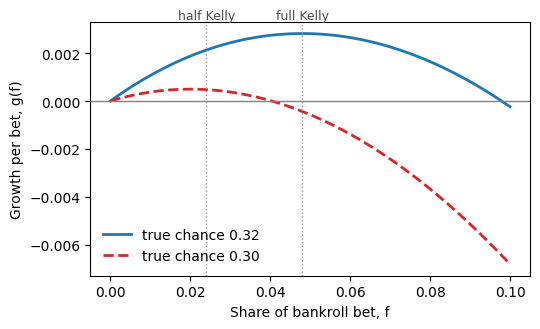

In [31]:
grid = np.linspace(0, 0.1, 200)
fig, ax = plt.subplots(figsize=(5.5, 3.4))
for c_true, color, ls in ((0.32, 'C0', '-'), (0.30, 'C3', '--')):
    ax.plot(grid, growth(grid, c_true, O3), color=color, ls=ls, lw=2,
            label=f'true chance {c_true:.2f}')
ax.axhline(0, color='0.5', lw=1)
top = ax.get_ylim()[1]
for f, name in ((half, 'half Kelly'), (full, 'full Kelly')):
    ax.axvline(f, color='0.6', ls=':', lw=1)
    ax.text(f, top, name, ha='center', va='bottom', fontsize=9, color='0.3')
ax.set_xlabel('Share of bankroll bet, f')
ax.set_ylabel('Growth per bet, g(f)')
ax.legend(frameon=False, loc='lower left')
fig.tight_layout()

Each curve rises to a peak and then falls. The peak is the best share for that true chance: 0.048 when the chance is 0.32, and 0.020 when it is 0.30. Past the peak, betting more makes the bankroll grow more slowly, and where a curve drops below 0 the bankroll shrinks. The red dashed curve ($c_{\text{true}} = 0.30$) drops below 0 at $f = 0.040$, so full Kelly (0.048) is already in the losing zone. Half Kelly (0.024) is above 0 on both the blue solid curve ($c_{\text{true}} = 0.32$) and the red dashed one.

How the race ended: horse 3 lost, and horse 8 won. In the what-if, Benter loses the \$240, and his bankroll is now \$9,760. His next stake is a share of \$9,760, not of \$10,000. A good bet can lose. The edge shows up only over many races.

#### Step 9. Put the whole recipe in one function

Steps 5, 7 and 8 fit in a few lines. The function takes the odds $O$, Benter's chance $c$, the bankroll, and the share of Kelly he uses (half, unless you say otherwise).

In [32]:
def benter_stake(O, c, bankroll, share=0.5):
    edge = c * O - 1             # Step 5: expected profit on a $1 bet
    if edge <= 0:
        return 0.0               # no edge, no bet
    f = edge / (O - 1)           # Step 7: the Kelly fraction
    return share * f * bankroll  # Step 8: dollars, at half Kelly unless told otherwise

c_step4 = race.loc[race.horse == 3, 'c'].item()
print(f'Step 4 chance {c_step4:.3f}: stake ${benter_stake(3.5, c_step4, 10_000):,.0f}')
print(f'Step 6 chance {0.32:.3f}: stake ${benter_stake(3.5, 0.32, 10_000):,.0f}')

Step 4 chance 0.244: stake $0
Step 6 chance 0.320: stake $240


With Step 4's chance the stake is \$0: no bet. With Step 6's what-if chance it is \$240.

#### Practice

1. Run `benter_stake` with $O = 3.5$ and $c = 0.30$, then with $c = 0.28$. Below which value of $c$ is the stake \$0? You found that number in Step 1.
2. Chapter 4 has two bets. "4/1" means a winning \$1 earns \$4 profit, so $O = 5$. "12/1" means $O = 13$. Before you run the second cell below, compute by hand the edge and the full Kelly fraction for 4/1 at $c = 1/4$ and for 12/1 at $c = 1/10$.

In [33]:
# Practice 1: your code here.

In [34]:
for O, c in ((5, 1/4), (13, 1/10)):
    edge = c * O - 1
    print(f'O = {O}, c = {c:.2f}: edge = {edge:.2f}, full Kelly f = {edge / (O - 1):.4f}')

O = 5, c = 0.25: edge = 0.25, full Kelly f = 0.0625
O = 13, c = 0.10: edge = 0.30, full Kelly f = 0.0250


The 4/1 bet has edge 0.25 and $f = 0.0625$, which is 1/16 of the bankroll. The 12/1 bet has the larger edge, 0.30, yet $f = 0.025$, which is 1/40, two and a half times less. Kelly divides the edge by the profit on a win, and the 12/1 horse loses 9 races in 10, so Kelly bets less on it.

What the recipe leaves out:

- In Hong Kong the odds come from the bets themselves (a pari-mutuel pool), so Benter's own money lowered the odds he was paid. His large bets had to be smaller than the formula says.
- When two or more horses in one race pass the test, their stakes are found together. Section 5 of the [Benter betting lab](https://vsokolov.org/labs/benter-lab.html) does this.
- The odds keep changing until the race starts, so the bet is placed before the final odds are known.

### Part B. Is the crowd right about favorites? (Chapter 13)

Step 4 assumed that the crowd gives favorites a little too little chance. Part B checks this on the favorite of every race in the data: 5,885 races from 30 November 1997 to 28 August 2005. It follows the Horse Race Betting example in Chapter 13. Part B is about the method (a logistic regression, a cutoff, an ROC curve), and the method works the same way with any input.

The column `public_prob` in this file is the crowd's chance $q$ of Step 3: $1/O$ divided by its sum over the race. Horse 3 of Part A, the favorite of race 1159, has `public_prob` 0.234 in this file, the same $q$ as in Step 3.

#### B1. How often do favorites win?

The next cell loads the file and shows its first rows. Each row is the favorite of one race. `win` is 1 if the favorite won and 0 if it lost.

In [35]:
races = pd.read_csv(DATA / 'hkjc-favorites.csv', parse_dates=['date'])
races.head()

,race_id,date,venue,field_size,public_prob,win
0,460,1997-11-30,ST,14,0.310066,0
1,461,1997-11-30,ST,14,0.323767,1
2,462,1997-11-30,ST,11,0.391897,1
3,463,1997-11-30,ST,14,0.164944,1
4,464,1997-11-30,ST,14,0.237016,1


The gap is the favorites' win rate minus their mean crowd chance. The next cell computes it for all races and for each track.

In [36]:
print(len(races), 'favorites', races.date.min().date(), 'to', races.date.max().date())
win = races.win.mean()
crowd = races.public_prob.mean()
print(f'win rate {win:.3f}')
print(f'mean crowd chance {crowd:.3f}')
print(f'gap {win - crowd:.3f}')
names = {'HV': 'Happy Valley', 'ST': 'Sha Tin'}
for venue, part in races.groupby('venue'):
    w, q = part.win.mean(), part.public_prob.mean()
    print(f'{names[venue]}: n {len(part)}, win {w:.3f}, crowd {q:.3f}, gap {w - q:.3f}')

5885 favorites 1997-11-30 to 2005-08-28
win rate 0.299
mean crowd chance 0.289
gap 0.010
Happy Valley: n 2187, win 0.281, crowd 0.270, gap 0.011
Sha Tin: n 3698, win 0.309, crowd 0.300, gap 0.009


Favorites won 29.9% of their races. Their mean crowd chance is 0.289, so the gap is 0.010, one percentage point. It is about the same at both tracks: 0.011 at Happy Valley (2,187 races) and 0.009 at Sha Tin (3,698 races). A positive gap means favorites won more often than the crowd's chance says. The gap is small: the standard error of the win rate is $\sqrt{0.299 \times 0.701 / 5885} = 0.006$, so the gap is about 1.6 standard errors, not enough to rule out chance.

#### B2. A logistic regression of win on the crowd's chance

Fit the chance $p$ that the favorite wins as a logistic regression on the file's crowd chance $q$ (the column `public_prob`):

$$
\log\frac{p}{1-p} = \beta_0 + \beta_1 q.
$$

This is the two-outcome version (win or lose) of the softmax in Section 3 of this notebook. It is a different model from Step 4, and $\beta_0$ and $\beta_1$ are not $\alpha$. The file also has the field size, which this fit does not use.

In [37]:
horse = smf.logit('win ~ public_prob', data=races).fit(disp=0)
horse.summary2().tables[1]

,Coef.,Std.Err.,z,P>|z|,[0.025,0.975]
Intercept,-2.198451,0.097080,-22.645698,1.538177e-113,-2.388725,-2.008177
public_prob,4.550162,0.307701,14.787586,1.761600e-49,3.947078,5.153246


The table gives $\beta_0 = -2.198$ and $\beta_1 = 4.550$. The next cell evaluates the fitted $p$ at the mean crowd chance.

In [38]:
q_bar = float(races.public_prob.mean())
p_hat = float(horse.predict(pd.DataFrame({'public_prob': [q_bar]})).iloc[0])
print(f'at mean crowd chance {q_bar:.3f}, fitted chance {p_hat:.3f}, gap {p_hat - q_bar:.3f}')

at mean crowd chance 0.289, fitted chance 0.292, gap 0.003


At the mean crowd chance 0.289, the fitted chance is 0.292, which is 0.003 above $q$. It is below the win rate 0.299 because the curve bends upward: the fitted chances average exactly 0.299, but the fitted chance at the average $q$ is lower. The next plot draws the fitted $p$ against $q$. The dashed line is $p = q$, where the crowd would be exactly right.

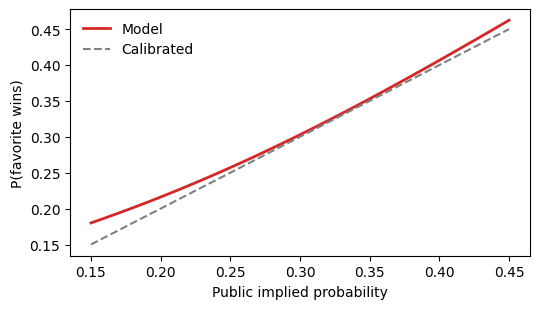

In [39]:
grid = np.linspace(0.15, 0.45, 100)
curve = horse.predict(pd.DataFrame({'public_prob': grid}))
fig, ax = plt.subplots(figsize=(5.5, 3.2))
ax.plot(grid, curve, color='C3', lw=2, label='Model')
ax.plot([0.15, 0.45], [0.15, 0.45], color='0.5', ls='--', label='Calibrated')
ax.set_xlabel('Public implied probability')
ax.set_ylabel('P(favorite wins)')
ax.legend(frameon=False)
fig.tight_layout()

The fitted curve is above the dashed line over the whole range, but close to it: less than one point above for $q$ between 0.25 and 0.40, and about three points at 0.15, where few favorites lie. In these races the crowd's chances for favorites are close to right.

#### B3. A cutoff turns $p$ into a yes-or-no bet

A cutoff $t$ means: bet on the favorite when $p > t$. Sensitivity is the share of winning favorites that get a bet. The false-positive rate is the share of losing favorites that get a bet, and it equals $1 - \text{specificity}$. The next cell draws the ROC curve, which shows both rates for every cutoff, and prints them at $t = 0.3$ and $t = 0.5$.

t = 0.3: sensitivity 0.501, false positive rate 0.337
t = 0.5: sensitivity 0.071, false positive rate 0.025


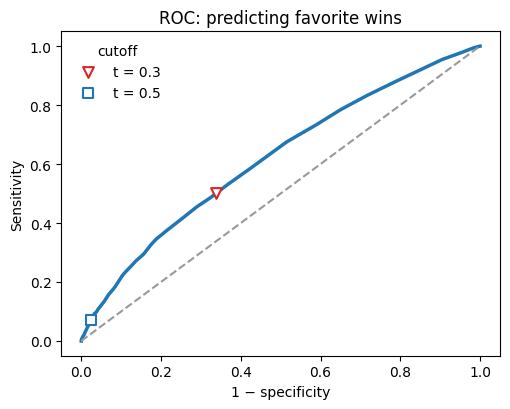

In [40]:
def roc(p, y, n_grid=100):
    p = np.asarray(p, dtype=float)
    y = np.asarray(y)
    t = np.linspace(0, 1, n_grid)
    # one column per cutoff: predict a win when p > t
    call = p[:, None] > t[None, :]
    specificity = np.mean(~call[y == 0], axis=0) if np.any(y == 0) else np.ones(n_grid)
    sensitivity = np.mean(call[y == 1], axis=0) if np.any(y == 1) else np.zeros(n_grid)
    return t, sensitivity, specificity

pred = horse.predict(races)
t, sensitivity, specificity = roc(pred, races.win.to_numpy())

def point(pred, y, t):
    y = np.asarray(y)
    # the book's marked points: losses with p < t, wins with p > t
    x = 1 - np.mean(pred[y == 0] < t)
    sens = np.mean(pred[y == 1] > t)
    return x, sens

fig, ax = plt.subplots(figsize=(5.2, 4.2))
ax.plot(1 - specificity, sensitivity, color='C0', lw=2.5)
ax.plot([0, 1], [0, 1], color='0.6', ls='--')
for t_mark, marker, color in ((0.3, 'v', 'C3'), (0.5, 's', 'C0')):
    x, sens = point(pred.to_numpy(), races.win.to_numpy(), t_mark)
    ax.scatter([x], [sens], marker=marker, s=60, facecolors='white', edgecolors=color, linewidths=1.5, label=f't = {t_mark}', zorder=3)
    print(f't = {t_mark}: sensitivity {sens:.3f}, false positive rate {x:.3f}')
ax.set_xlabel('1 − specificity')
ax.set_ylabel('Sensitivity')
ax.set_title('ROC: predicting favorite wins')
ax.legend(frameon=False, title='cutoff')
fig.tight_layout()

At $t = 0.3$ the rule bets on 50.1% of the winning favorites and on 33.7% of the losing ones. At $t = 0.5$ it bets on only 7.1% of the winners and 2.5% of the losers. A higher cutoff means fewer bets of both kinds.

#### B4. Expected profit at a cutoff

Chapter 13 simplifies the payout: every bet is paid at odds $O = 2.5$, so a winning \$1 bet earns \$1.50 and a losing one costs \$1. The expected profit per race of the rule "bet \$1 on the favorite when $p > t$" is

$$
\mathrm{E}(\text{profit} \mid t) = P(\text{win})\cdot\text{sensitivity}(t)\cdot 1.5 \;-\; P(\text{lose})\cdot\bigl(1-\text{specificity}(t)\bigr)\cdot 1.
$$

The next cell computes it at three cutoffs.

In [41]:
p_win = races.win.mean()
for t_cut in (0.3, 0.4, 0.5):
    fpr, sens = point(pred.to_numpy(), races.win.to_numpy(), t_cut)
    profit = p_win * sens * 1.5 - (1 - p_win) * fpr * 1
    print(f't = {t_cut}: expected profit per race ${profit:.3f}')

t = 0.3: expected profit per race $-0.012
t = 0.4: expected profit per race $0.027
t = 0.5: expected profit per race $0.015


The rule loses 1.2 cents per race at $t = 0.3$, makes 2.7 cents at $t = 0.4$, and makes 1.5 cents at $t = 0.5$. The best of the three is $t = 0.4$, and 0.4 is the break-even chance of Step 5: a bet at $O = 2.5$ breaks even at $1/O = 1/2.5 = 0.4$. The rule is the same as in Part A: bet only when the chance of winning beats the break-even chance. The cutoff decides whether to bet. Kelly (Step 7) decides how much.

The profit comes from the assumed payout, not from the data. The favorites with $p > 0.4$ are the strongest ones, and their real odds are short: the median is 1.8, not 2.5. At their real odds the same 808 bets lose 16 cents per dollar, close to the 18% cut of Step 2. (This file has no odds column; the numbers come from the full race data that Chapter 13 uses, where the book makes the same calculation.)